# 02 · EDA: Claims
**BEV vs. ICE Motor Property Insurance**

**Purpose:** compare BEV, Hybrid and ICE on the three parts of the pure premium:
1. **Frequency**: claims per vehicle-year of exposure.
2. **Severity**: own-damage (repair) cost per claim.
3. **Total-loss incidence**: write-off rate and its cost impact.

**Inputs:** `data/processed/claims_cleaned.rds` and `data/processed/policies_cleaned.rds`, both written by `src/01_clean_datasets.R`. The two files are not joined yet; this notebook inner-joins them on `Policy_ID` **for EDA only** (§1.4), to get powertrain, exposure and vehicle value. The definitive join belongs in `src/01_etl_merge_and_clean.R`.

**Field mapping:** the extract has no single `Claim_Amount` or `Total_Loss` column. We use:
- `Own_Damage_Amount`: repair cost of the insured vehicle. This is the **severity measure**, because powertrain acts directly on it.
- `TP_Damage_Amount`: third-party property damage. It depends mainly on the *other* vehicle, so it is reported only as a side check.
- `is_total_loss_clean`: write-off flag (the raw `Is_Total_Loss`, reset to FALSE where own damage = 0).

## 1. Setup & Data Ingestion

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(lubridate)
  library(patchwork)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

pt_colours <- c(BEV = "#1b9e77", Hybrid = "#7570b3", ICE = "#d95f02")

# Works whether the notebook runs from notebooks/ or from the repository root
find_processed <- function(file) {
  path <- file.path(c("../data/processed", "data/processed"), file) |> keep(file.exists) |> first()
  if (is.na(path)) stop("Cannot find ", file, " (run src/01_clean_datasets.R first)")
  path
}

# Quantile summary of a numeric variable by powertrain
severity_summary <- function(data, var) {
  data |>
    filter(!is.na({{ var }})) |>
    group_by(Powertrain) |>
    summarise(claims = n(),
              mean   = mean({{ var }}),
              median = median({{ var }}),
              p25    = quantile({{ var }}, 0.25),
              p75    = quantile({{ var }}, 0.75),
              p95    = quantile({{ var }}, 0.95),
              p99    = quantile({{ var }}, 0.99))
}

# Display label for the canonical claim types ("Natural_Hazard" -> "Natural Hazard")
pretty_type <- function(x) str_replace_all(x, "_", " ")

### 1.1 Load cleaned claims and inspect structure
The amounts are already numeric, `Accident_Date` is a `Date` and `Claim_Type` holds 8 canonical labels.

In [2]:
claims <- read_rds(find_processed("claims_cleaned.rds"))

cat("Rows:", nrow(claims), "| Columns:", ncol(claims), "\n\n")
glimpse(claims)

Rows: 6569 | Columns: 9 



Rows: 6,569
Columns: 9
$ Claim_ID            <chr> "C849378", "C733412", "C928394", "C826146", "C7334…
$ Policy_ID           <chr> "P2243106", "P2965488", "P2465223", "P2401991", "P…
$ Accident_Date       <date> 2024-07-05, 2025-02-25, 2024-09-13, 2024-06-04, 2…
$ Claim_Type          <chr> "Collision_With_TP", "Collision_No_TP", "Collision…
$ Own_Damage_Amount   <dbl> 0.00, 5576.30, 1313.01, 1410.41, 5972.74, 983.65, …
$ TP_Damage_Amount    <dbl> 3967.45, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 14612…
$ Is_Total_Loss       <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ is_total_loss_clean <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, F…
$ is_cat_event        <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, F…


In [3]:
claims |>
  summarise(across(everything(), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") |>
  mutate(pct_missing = percent(n_missing / nrow(claims), accuracy = 0.1))

column,n_missing,pct_missing
<chr>,<int>,<chr>
Claim_ID,0,0.0%
Policy_ID,0,0.0%
Accident_Date,0,0.0%
Claim_Type,0,0.0%
Own_Damage_Amount,0,0.0%
TP_Damage_Amount,0,0.0%
Is_Total_Loss,0,0.0%
is_total_loss_clean,0,0.0%
is_cat_event,0,0.0%


### 1.2 Field audit: cleaning record and residual checks
The claims rows of `cleaning_log.csv` record every fix and drop made by `src/01_clean_datasets.R` (raw 6,664 → 6,569 rows). The checks below confirm the result: no NA, a unique `Claim_ID`, non-negative amounts and 8 claim types. `TP_Damage_Amount` = 0 for most claims is **structural**: there is no third party in single-vehicle, theft or weather claims.

In [4]:
read_csv(find_processed("cleaning_log.csv"), show_col_types = FALSE) |>
  filter(dataset == "claims") |>
  select(-dataset)

tribble(
  ~check,                                  ~value,
  "Cells with NA",                         sum(is.na(claims)),
  "Duplicate Claim_ID",                    sum(duplicated(claims$Claim_ID)),
  "Own_Damage_Amount < 0",                 sum(claims$Own_Damage_Amount < 0),
  "Own_Damage_Amount = 0 (kept)",          sum(claims$Own_Damage_Amount == 0),
  "TP_Damage_Amount = 0",                  sum(claims$TP_Damage_Amount == 0),
  "Is_Total_Loss = 1 (raw flag)",          sum(claims$Is_Total_Loss == 1),
  "is_total_loss_clean",                   sum(claims$is_total_loss_clean),
  "is_cat_event",                          sum(claims$is_cat_event)
)

cat("\nAccident dates:  ", format(range(claims$Accident_Date)),
    "\nOwn damage range:", comma(range(claims$Own_Damage_Amount), prefix = "₪"),
    "\nTP damage range: ", comma(range(claims$TP_Damage_Amount), prefix = "₪"), "\n")
count(claims, Claim_Type, sort = TRUE)

step,action,rows_before,rows_after,rows_affected
<chr>,<chr>,<dbl>,<dbl>,<dbl>
B1 remove exact duplicates,drop,6664,6604,60
B2 normalise Policy_ID,fix,6604,6604,40
B3 parse Accident_Date,fix,6604,6604,0
B4a parse amounts (text -> num),fix,6604,6604,336
B4b drop Own_Damage_Amount < 0,drop,6604,6569,35
B4c blank TP_Damage_Amount -> 0,fix,6569,6569,4227
B5 recode Claim_Type,fix,6569,6569,511
B6a flag CAT event 2025-01-19,flag,6569,6569,532
B6b total-loss flag reset (OD = 0),flag,6569,6569,9


check,value
<chr>,<int>
Cells with NA,0
Duplicate Claim_ID,0
Own_Damage_Amount < 0,0
Own_Damage_Amount = 0 (kept),350
TP_Damage_Amount = 0,4376
Is_Total_Loss = 1 (raw flag),622
is_total_loss_clean,613
is_cat_event,532



Accident dates:   2024-01-03 2025-12-23 
Own damage range: ₪0 ₪1,557,232 
TP damage range:  ₪0 ₪238,832 


Claim_Type,n
<chr>,<int>
Collision_With_TP,2173
Single_Vehicle_Accident,1436
Collision_No_TP,1234
Natural_Hazard,848
Malicious_Damage,441
Theft,233
Unspecified,164
Fire,40


### 1.3 Exposure base from cleaned policies
`policies_cleaned` already has one row per `Policy_ID`, a valid exposure in years (0 < exposure ≤ 1.01), a trimmed `Powertrain` factor and `Vehicle_Value` in ₪ (NA where unknown).

In [5]:
policies <- read_rds(find_processed("policies_cleaned.rds")) |>
  select(Policy_ID, Powertrain, Start_Date, End_Date, exposure, Vehicle_Value)

cat("Policies:", nrow(policies), "| exposure years:", comma(sum(policies$exposure)),
    "| missing Vehicle_Value:", sum(is.na(policies$Vehicle_Value)), "\n")

Policies: 38309 | exposure years: 36,331 | missing Vehicle_Value: 363 


### 1.4 EDA-only join to policies
**These rules are EDA-only.** They anticipate the merge script `src/01_etl_merge_and_clean.R`, which will apply them definitively.
- Inner-join to policies, which drops orphan claims (counted here, broken down in §5).
- Flag **in_period**: the accident falls inside the policy's exposure window. Only in-period claims are analysed.
- Flag **valid_amount**: own damage > 0 and ≤ 2 × vehicle value (severity screen).

The CAT event (2025-01-19 storm, see §2.3) comes from `is_cat_event` in the cleaned file.

In [6]:
n_orphans <- sum(!claims$Policy_ID %in% policies$Policy_ID)

claims_joined <- claims |>
  inner_join(policies, by = "Policy_ID") |>
  mutate(in_period    = between(Accident_Date, Start_Date, End_Date),
         damage_ratio = Own_Damage_Amount / Vehicle_Value,
         valid_amount = Own_Damage_Amount > 0 & (is.na(damage_ratio) | damage_ratio <= 2))

cat("Cleaned claims:", nrow(claims), "| orphans dropped:", n_orphans,
    "| joined:", nrow(claims_joined), "| in period:", sum(claims_joined$in_period), "\n")

# Analysis base: claims that fall within the policy's exposure window
claims_ip <- filter(claims_joined, in_period)

Cleaned claims: 6569 | orphans dropped: 51 | joined: 6518 | in period: 6448 


## 2. Claim Volume & Frequency
### 2.1 Claims per policy

In [7]:
claim_counts <- policies |>
  left_join(count(claims_ip, Policy_ID, name = "n_claims"), by = "Policy_ID") |>
  mutate(n_claims = replace_na(n_claims, 0L))

claim_counts |>
  mutate(claims_band = case_when(n_claims == 0 ~ "0", n_claims == 1 ~ "1", .default = "2+")) |>
  count(Powertrain, claims_band) |>
  group_by(Powertrain) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
  select(-n) |>
  pivot_wider(names_from = claims_band, values_from = share)

Powertrain,0,1,2+
<fct>,<chr>,<chr>,<chr>
ICE,85.4%,13.0%,1.7%
Hybrid,85.0%,13.0%,2.0%
BEV,84.7%,13.6%,1.7%


### 2.2 Claim frequency per vehicle-year
Frequency = claims / earned exposure, with an approximate 95% Poisson confidence interval. The 2025-01-19 CAT event is shown separately, because catastrophe losses are normally priced with a separate loading.

**Why the storm is excluded:** the 2025-01-19 storm is a catastrophe event: a rare, one-off tail loss that cannot be rated from a policy's own characteristics. Insurers cover such events through reinsurance and a separate catastrophe loading, not through the baseline pure-premium tariff, so it is left out of the attritional analysis. The claims stay in the data, flagged as `is_cat_event`.

In [8]:
frequency <- claim_counts |>
  group_by(Powertrain) |>
  summarise(exposure_years = sum(exposure)) |>
  left_join(claims_ip |>
              group_by(Powertrain) |>
              summarise(claims_all = n(), claims_ex_cat = sum(!is_cat_event)),
            by = "Powertrain") |>
  mutate(freq_all    = claims_all / exposure_years,
         freq_ex_cat = claims_ex_cat / exposure_years,
         ci_low      = (claims_ex_cat - 1.96 * sqrt(claims_ex_cat)) / exposure_years,
         ci_high     = (claims_ex_cat + 1.96 * sqrt(claims_ex_cat)) / exposure_years)

frequency |>
  mutate(exposure_years = comma(exposure_years, accuracy = 1),
         across(c(freq_all, freq_ex_cat, ci_low, ci_high), ~ percent(.x, accuracy = 0.1)))

Powertrain,exposure_years,claims_all,claims_ex_cat,freq_all,freq_ex_cat,ci_low,ci_high
<fct>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,"24,506",4284,3937,17.5%,16.1%,15.6%,16.6%
Hybrid,"7,843",1428,1307,18.2%,16.7%,15.8%,17.6%
BEV,"3,982",736,672,18.5%,16.9%,15.6%,18.2%


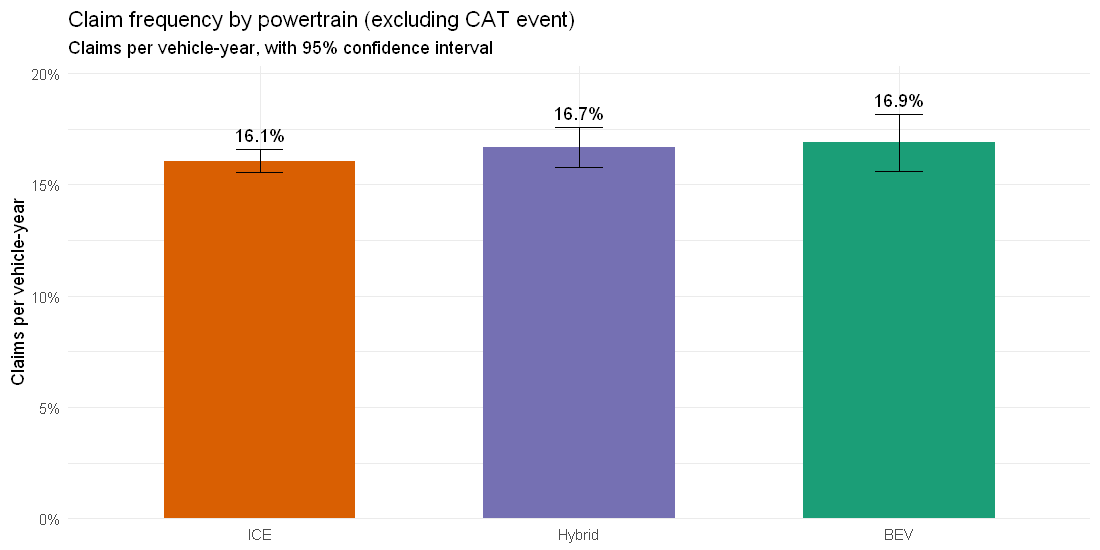

In [9]:
ggplot(frequency, aes(Powertrain, freq_ex_cat, fill = Powertrain)) +
  geom_col(width = 0.6) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.15) +
  geom_text(aes(y = ci_high, label = percent(freq_ex_cat, accuracy = 0.1)), vjust = -0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Claim frequency by powertrain (excluding CAT event)",
       subtitle = "Claims per vehicle-year, with 95% confidence interval",
       x = NULL, y = "Claims per vehicle-year")

### 2.3 Monthly incidence trend
Raw monthly claim counts mostly reflect how much exposure is in force, which ramps up through 2024 and runs off through 2025. We therefore plot the **annualised frequency**: monthly claims divided by the exposure earned in that month.

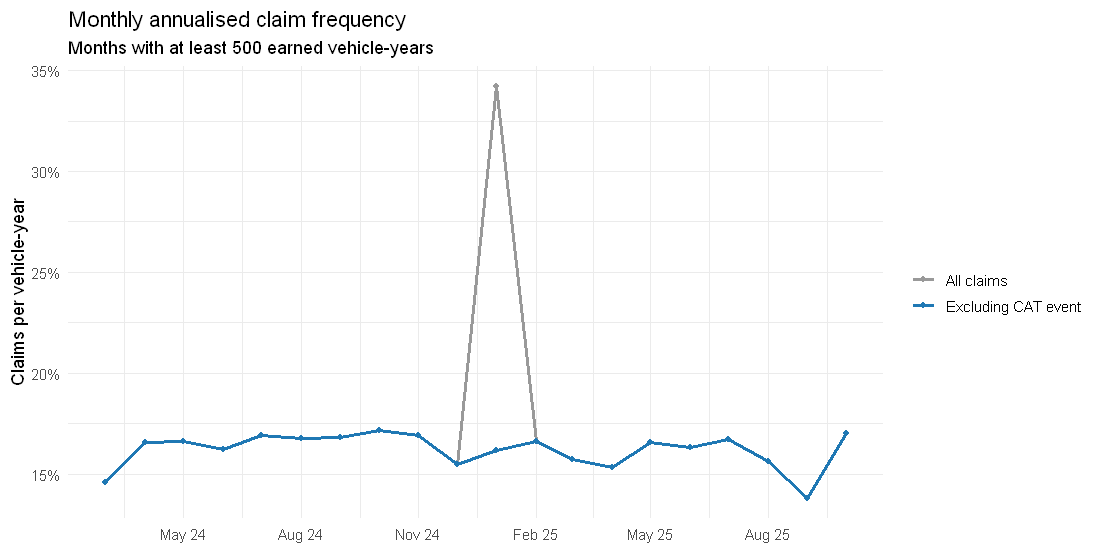

In [10]:
months <- tibble(month = seq(floor_date(min(policies$Start_Date), "month"),
                             floor_date(max(policies$End_Date),   "month"),
                             by = "month"))

earned <- policies |>
  select(Start_Date, End_Date) |>
  cross_join(months) |>
  mutate(days = as.numeric(pmin(End_Date, ceiling_date(month, "month") - 1) -
                           pmax(Start_Date, month) + 1)) |>
  filter(days > 0) |>
  summarise(exposure_years = sum(days) / 365.25, .by = month)

monthly <- claims_ip |>
  mutate(month = floor_date(Accident_Date, "month")) |>
  summarise(`All claims` = n(), `Excluding CAT event` = sum(!is_cat_event), .by = month) |>
  inner_join(earned, by = "month") |>
  filter(exposure_years >= 500) |>              # drop thin run-in / run-off months
  pivot_longer(c(`All claims`, `Excluding CAT event`), names_to = "series", values_to = "claims") |>
  mutate(frequency = claims / exposure_years)

ggplot(monthly, aes(month, frequency, colour = series)) +
  geom_line(linewidth = 1) +
  geom_point(size = 1.5) +
  scale_colour_manual(values = c("grey60", "#1f78b4")) +
  scale_y_continuous(labels = percent) +
  scale_x_date(date_breaks = "3 months",
               labels = \(x) paste(month.abb[month(x)], format(x, "%y"))) +   # locale-independent
  labs(title = "Monthly annualised claim frequency",
       subtitle = "Months with at least 500 earned vehicle-years",
       x = NULL, y = "Claims per vehicle-year", colour = NULL)

In [11]:
# The January 2025 spike: all claims on the CAT date (is_cat_event flags the Natural_Hazard ones)
claims_ip |>
  filter(Accident_Date == as_date("2025-01-19")) |>
  count(claim_type = pretty_type(Claim_Type), is_cat_event, sort = TRUE) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1))

claim_type,is_cat_event,n,share
<chr>,<lgl>,<int>,<chr>
Natural Hazard,TRUE,532,95.3%
Unspecified,FALSE,8,1.4%
Collision No TP,FALSE,7,1.3%
Collision With TP,FALSE,7,1.3%
Malicious Damage,FALSE,2,0.4%
Single Vehicle Accident,FALSE,2,0.4%


### 2.4 Claim-type mix (excluding CAT event)

In [12]:
claims_ip |>
  filter(!is_cat_event) |>
  count(Powertrain, claim_type = pretty_type(Claim_Type)) |>
  group_by(Powertrain) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
  select(-n) |>
  pivot_wider(names_from = Powertrain, values_from = share, values_fill = "0.0%") |>
  arrange(claim_type)

claim_type,ICE,Hybrid,BEV
<chr>,<chr>,<chr>,<chr>
Collision No TP,20.2%,20.7%,20.5%
Collision With TP,36.4%,34.6%,37.4%
Fire,0.7%,0.8%,0.4%
Malicious Damage,7.3%,7.3%,7.9%
Natural Hazard,5.5%,4.4%,4.8%
Single Vehicle Accident,23.5%,23.3%,26.5%
Theft,3.5%,6.6%,0.7%
Unspecified,3.0%,2.4%,1.8%


## 3. Claim Severity (Own-Damage Cost per Claim)
Base: attritional claims (CAT event excluded) with a valid own-damage amount.

In [13]:
sev <- claims_ip |> filter(!is_cat_event, valid_amount)

severity_summary(sev, Own_Damage_Amount) |>
  mutate(mean_to_median = number(mean / median, accuracy = 0.01),
         across(mean:p99, ~ comma(.x, accuracy = 1, prefix = "₪")))

Powertrain,claims,mean,median,p25,p75,p95,p99,mean_to_median
<fct>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ICE,3704,"₪11,041","₪4,709","₪2,148","₪11,062","₪46,994","₪100,225",2.34
Hybrid,1240,"₪18,187","₪7,055","₪3,374","₪15,650","₪91,515","₪142,601",2.58
BEV,631,"₪20,935","₪9,360","₪4,317","₪23,850","₪87,286","₪148,660",2.24


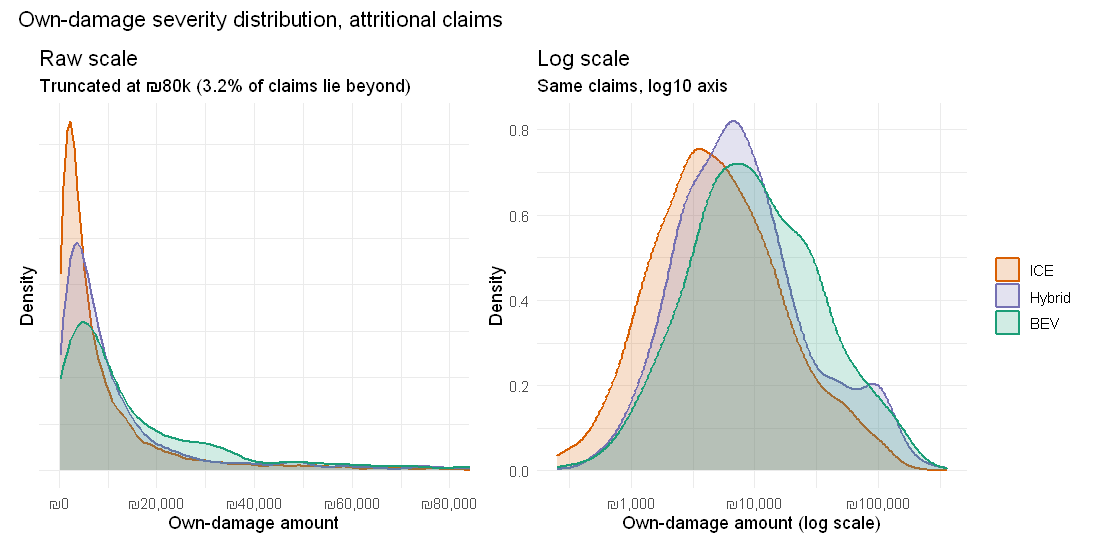

In [14]:
# Raw vs. log scale: why the tests and GLMs work with log(cost)
raw_cap   <- 80000
share_cut <- percent(mean(sev$Own_Damage_Amount > raw_cap), accuracy = 0.1)

p_raw <- ggplot(sev, aes(Own_Damage_Amount, fill = Powertrain, colour = Powertrain)) +
  geom_density(alpha = 0.2, linewidth = 0.8) +
  coord_cartesian(xlim = c(0, raw_cap)) +                     # zoom only; density uses all claims
  scale_x_continuous(labels = label_comma(prefix = "₪")) +
  scale_y_continuous(labels = NULL) +                          # density units are not meaningful here
  labs(title = "Raw scale",
       subtitle = paste0("Truncated at ₪80k (", share_cut, " of claims lie beyond)"),
       x = "Own-damage amount", y = "Density")

p_log <- ggplot(sev, aes(Own_Damage_Amount, fill = Powertrain, colour = Powertrain)) +
  geom_density(alpha = 0.2, linewidth = 0.8) +
  scale_x_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Log scale", subtitle = "Same claims, log10 axis",
       x = "Own-damage amount (log scale)", y = "Density")

(p_raw + p_log) +
  plot_layout(guides = "collect") +
  plot_annotation(title = "Own-damage severity distribution, attritional claims") &
  scale_fill_manual(values = pt_colours, name = NULL) &
  scale_colour_manual(values = pt_colours, name = NULL)

On the raw scale, own-damage costs are strongly right-skewed: a long tail of large claims, and a mean 2.2–2.6× the median. On the log scale the same claims form a roughly symmetric, bell-shaped curve. This is why the hypothesis tests (notebook 03) compare **log** costs and the severity GLM (notebook 04) uses a log link.

### 3.1 Systematic shift or heavy tail?
The **quantile ratio** BEV ÷ ICE across the distribution answers this directly. A flat line means a uniform shift (every claim costs proportionally more), while a line that rises towards the right means the gap is driven by large claims.

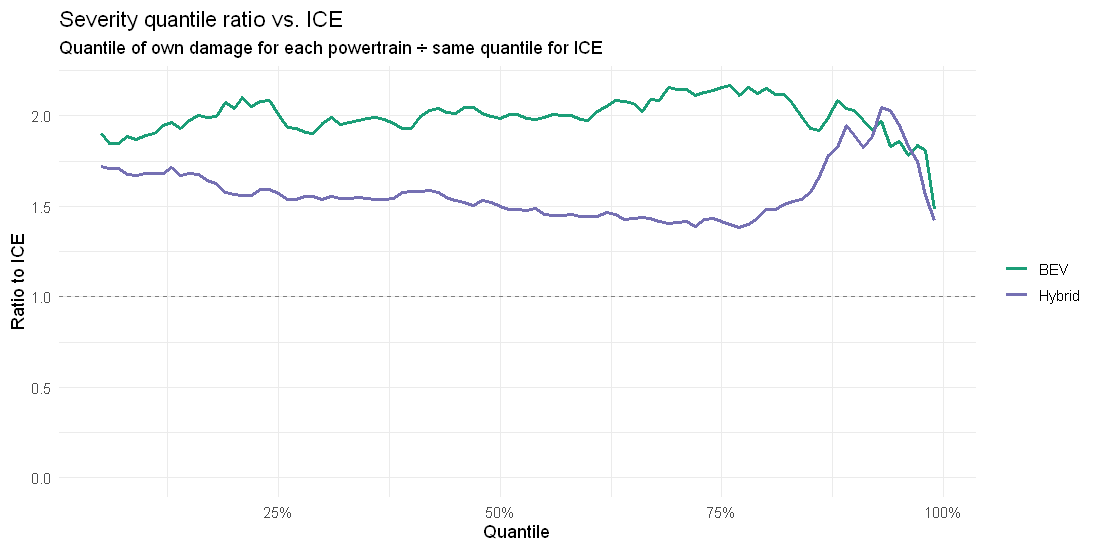

In [15]:
probs <- seq(0.05, 0.99, by = 0.01)

quantile_ratio <- map(c("BEV", "Hybrid"), \(pt) {
  tibble(prob     = probs,
         ratio    = quantile(sev$Own_Damage_Amount[sev$Powertrain == pt],  probs) /
                    quantile(sev$Own_Damage_Amount[sev$Powertrain == "ICE"], probs),
         Powertrain = pt)
}) |> list_rbind()

ggplot(quantile_ratio, aes(prob, ratio, colour = Powertrain)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = "grey50") +
  geom_line(linewidth = 1) +
  scale_colour_manual(values = pt_colours) +
  scale_x_continuous(labels = percent) +
  scale_y_continuous(limits = c(0, NA)) +
  labs(title = "Severity quantile ratio vs. ICE",
       subtitle = "Quantile of own damage for each powertrain ÷ same quantile for ICE",
       x = "Quantile", y = "Ratio to ICE", colour = NULL)

### 3.2 Severity relative to vehicle value
BEVs are worth about 2.35× ICE vehicles (notebook 01). The **damage ratio** (own damage ÷ vehicle value) shows how much of the severity gap remains once the sum insured is taken into account.

In [16]:
severity_summary(filter(sev, !is.na(damage_ratio)), damage_ratio) |>
  select(Powertrain, claims, mean, median, p75, p95) |>
  mutate(across(mean:p95, ~ percent(.x, accuracy = 0.1)))

Powertrain,claims,mean,median,p75,p95
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,3650,20.0%,9.3%,21.3%,91.1%
Hybrid,1239,19.4%,8.0%,17.6%,92.3%
BEV,631,17.3%,7.2%,17.4%,89.7%


In [17]:
# Side check: third-party property damage (Collision_With_TP claims only)
sev_tp <- claims_ip |> filter(!is_cat_event, Claim_Type == "Collision_With_TP", TP_Damage_Amount > 0)

severity_summary(sev_tp, TP_Damage_Amount) |>
  select(Powertrain, claims, mean, median, p95) |>
  mutate(across(mean:p95, ~ comma(.x, accuracy = 1, prefix = "₪")))

Powertrain,claims,mean,median,p95
<fct>,<int>,<chr>,<chr>,<chr>
ICE,1432,"₪13,323","₪8,539","₪39,016"
Hybrid,452,"₪11,880","₪7,658","₪35,842"
BEV,251,"₪12,194","₪8,265","₪39,936"


## 4. Total Loss / Write-off Analysis
### 4.1 Total-loss rate by powertrain
Theft write-offs are unrelated to repair economics, so the rate is shown both **with and without theft**. The ex-theft rate is the relevant test of the battery-replacement-threshold hypothesis.

In [18]:
tl_base <- claims_ip |> filter(!is_cat_event)

tl_rates <- bind_rows(
  `All claims`        = tl_base,
  `Excluding theft`   = filter(tl_base, Claim_Type != "Theft"),
  .id = "basis"
) |>
  group_by(basis, Powertrain) |>
  summarise(claims = n(), total_losses = sum(is_total_loss_clean)) |>
  mutate(rate    = total_losses / claims,
         ci_low  = rate - 1.96 * sqrt(rate * (1 - rate) / claims),
         ci_high = rate + 1.96 * sqrt(rate * (1 - rate) / claims)) |>
  ungroup()

tl_rates |> mutate(across(rate:ci_high, ~ percent(.x, accuracy = 0.1)))

basis,Powertrain,claims,total_losses,rate,ci_low,ci_high
<chr>,<fct>,<int>,<int>,<chr>,<chr>,<chr>
All claims,ICE,3937,399,10.1%,9.2%,11.1%
All claims,Hybrid,1307,141,10.8%,9.1%,12.5%
All claims,BEV,672,57,8.5%,6.4%,10.6%
Excluding theft,ICE,3801,294,7.7%,6.9%,8.6%
Excluding theft,Hybrid,1221,71,5.8%,4.5%,7.1%
Excluding theft,BEV,667,54,8.1%,6.0%,10.2%


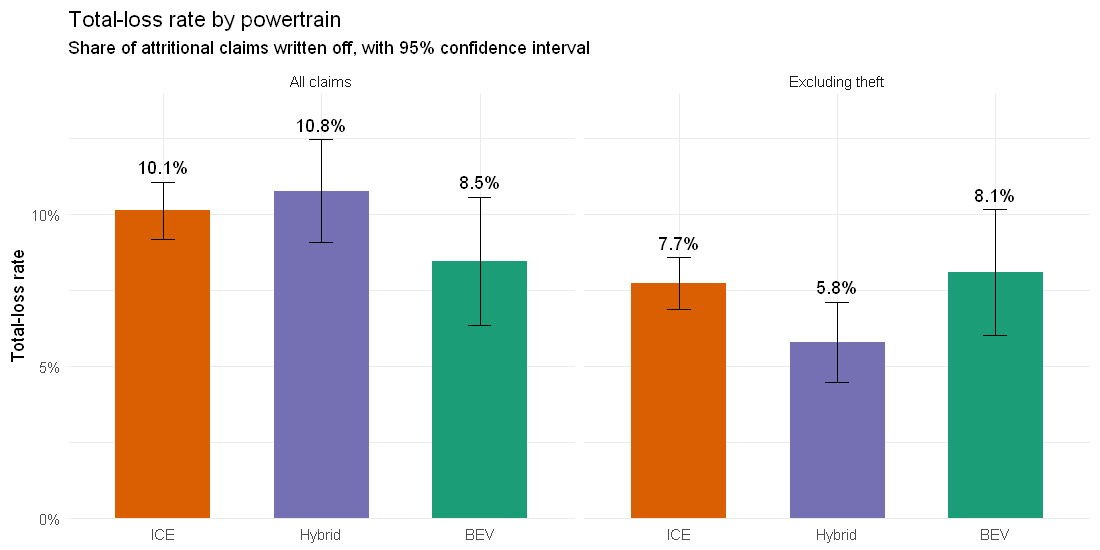

In [19]:
ggplot(tl_rates, aes(Powertrain, rate, fill = Powertrain)) +
  geom_col(width = 0.6) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.15) +
  geom_text(aes(y = ci_high, label = percent(rate, accuracy = 0.1)), vjust = -0.6) +
  facet_wrap(~ basis) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Total-loss rate by powertrain",
       subtitle = "Share of attritional claims written off, with 95% confidence interval",
       x = NULL, y = "Total-loss rate")

### 4.2 Partial vs. total loss cost

In [20]:
sev |>
  mutate(loss_type = if_else(is_total_loss_clean, "Total loss", "Partial loss")) |>
  group_by(Powertrain, loss_type) |>
  summarise(claims             = n(),
            median_cost        = median(Own_Damage_Amount),
            mean_cost          = mean(Own_Damage_Amount),
            median_damage_ratio = median(damage_ratio, na.rm = TRUE),
            total_cost         = sum(Own_Damage_Amount)) |>
  mutate(share_of_cost = percent(total_cost / sum(total_cost), accuracy = 0.1)) |>
  ungroup() |>
  mutate(across(c(median_cost, mean_cost), ~ comma(.x, accuracy = 1, prefix = "₪")),
         median_damage_ratio = percent(median_damage_ratio, accuracy = 1)) |>
  select(-total_cost)

Powertrain,loss_type,claims,median_cost,mean_cost,median_damage_ratio,share_of_cost
<fct>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,Partial loss,3305,"₪3,982","₪6,721",8%,54.3%
ICE,Total loss,399,"₪39,142","₪46,828",91%,45.7%
Hybrid,Partial loss,1099,"₪6,025","₪9,474",7%,46.2%
Hybrid,Total loss,141,"₪84,357","₪86,103",91%,53.8%
BEV,Partial loss,574,"₪8,392","₪14,134",6%,61.4%
BEV,Total loss,57,"₪83,342","₪89,424",91%,38.6%


## 5. Data Quality Audit
The file-level fixes are recorded in §1.2. What remains are the **join diagnostics** against `policies_cleaned`. They are EDA-only here and are action items for the merge script `src/01_etl_merge_and_clean.R`.
- **51 orphans** = 32 true orphans (`Policy_ID` absent from the raw policies too) + 5 claims on the dropped `1900`-start policies + 14 claims on the dropped pre-2012 BEV policies.
- **0 accidents before start:** the date swaps in the policy cleaning fixed all of them. **70 accidents after end** remain.

In [21]:
tribble(
  ~issue,                                                  ~records,
  "Orphan claims (Policy_ID not in policies_cleaned)",     n_orphans,
  "Accident before policy start",                          sum(claims_joined$Accident_Date < claims_joined$Start_Date),
  "Accident after policy end",                             sum(claims_joined$Accident_Date > claims_joined$End_Date),
  "Policy has no Vehicle_Value",                           sum(is.na(claims_joined$Vehicle_Value)),
  "Own damage > 2 × vehicle value (likely entry error)",   sum(claims_joined$damage_ratio > 2, na.rm = TRUE),
  "Clean total loss with damage ratio < 50%",              sum(claims_joined$is_total_loss_clean & claims_joined$damage_ratio < 0.5, na.rm = TRUE),
  "CAT event claims (is_cat_event)",                       sum(claims_joined$is_cat_event)
)

issue,records
<chr>,<int>
Orphan claims (Policy_ID not in policies_cleaned),51
Accident before policy start,0
Accident after policy end,70
Policy has no Vehicle_Value,62
Own damage > 2 × vehicle value (likely entry error),12
Clean total loss with damage ratio < 50%,25
CAT event claims (is_cat_event),532


## 6. Key Findings & Data Cleaning Summary

*This notebook reads the cleaned files written by `src/01_clean_datasets.R` and joins them to policies for EDA only (§1.4). Counts in the table below come from `data/processed/cleaning_log.csv`, after exact duplicates are removed.*

**Main anomalies in the raw claims data, and how `src/01_clean_datasets.R` handles them**

| Anomaly (rows) | Action | Rationale |
|---|---|---|
| Exact duplicate rows (60) | Drop | No `Claim_ID` has conflicting content, so `Claim_ID` is now a key. |
| Lowercase / padded `Policy_ID` (40) | Fix: `toupper(trim)` | With raw keys 72 claims were unmatched; only 32 are true orphans. |
| Amounts as text, `₪` and commas (340) | Fix: parse and round to 2 dp | All of them parse. |
| Own damage < 0 (35) | Drop | All are Collision_No_TP, with no parent claim to net against. |
| Blank TP amount (4,227) | Fix → 0 | "No TP" was stored both as blank and as `0.0`. |
| Claim_Type variants / blank / `Accident` (511) | Fix: recode to 8 labels | 41 blanks with TP > 0 become Collision_With_TP. The other blanks and `Accident` become `Unspecified`. |
| CAT storm on 2025-01-19 (532) | Flag `is_cat_event` (date and Natural_Hazard) | It is real but non-recurring loss, so it is kept and gets a sensitivity run without it. |
| Total loss with own damage = 0 (9) | Flag: `is_total_loss_clean` = FALSE | The raw `Is_Total_Loss` is kept alongside it. |
| Own damage = 0 (350) | Keep | The own-damage claim definition (OD > 0) is applied at the frequency/severity stage. |

**Key EDA findings** (6,448 in-period claims on the cleaned files)
1. **Frequency barely differs by powertrain.** Excluding the CAT event, the frequency is 16.9% for BEV (95% CI 15.6–18.2%), 16.1% for ICE and 16.7% for Hybrid, so BEV/ICE ≈ 1.05. About 85% of policies have no claim, 13% have one and 2% have two or more.
2. **A single-day catastrophe.** `is_cat_event` flags 532 Natural_Hazard claims on 2025-01-19 (26 ordinary claims fall on the same day). The event pushes January 2025 to ~34% annualised frequency, against ~16% in other months. Otherwise there is no trend.
3. **BEV severity is ≈ 2× ICE, a uniform shift rather than a heavy tail.** Median own damage is ₪9.4k vs. ₪4.7k, and p99 is ₪149k vs. ₪100k. The quantile ratio stays ≈ 2 (1.9–2.2) from the 5th to the 95th percentile and falls to ≈ 1.5 at the 99th. Relative to value, BEVs are *not* dearer: the median damage ratio is 7.2% vs. 9.3%. TP damage is similar across powertrains (median ≈ ₪7.7–8.5k).
4. **No clear battery-driven write-off effect.** Excluding theft, the clean total-loss rate is 8.1% for BEV vs. 7.7% for ICE (Hybrid 5.8%), with overlapping confidence intervals. There are only 57 BEV total losses, and every powertrain is written off at a median damage ratio of 91%. Theft makes up 6.6% of Hybrid claims, 3.5% of ICE claims and 0.7% of BEV claims.

**GLM stage (notebook 04)**
- **Frequency:** Poisson with a log link and `offset(log(exposure))`; switch to Negative Binomial if the data are overdispersed. Exclude the CAT event.
- **Severity:** Gamma with a log link on OD > 0, including `log(Vehicle_Value)`.
- **Total loss:** logistic, with claim type as a covariate.
- **All models:** ICE is the reference level, and the CAT event is priced as a separate loading.

**Policy-side dependencies** (from `policies_cleaned`)
- **Dropped policies:** 1 invalid re-issue (its `Policy_ID` survives on the valid record), 25 with a `1900` start and 78 BEVs with model year < 2012; the missing / impossible `Vehicle_Age` rule dropped 0 rows. The 1900 and old-BEV drops leave 5 and 14 claims without a policy.
- **Reclassified policies:** the 75 BEV + PHEV policies count as Hybrid.
- **Repaired dates:** the date swaps fix every "accident before start" case.
- **Re-issues:** re-issued policies are collapsed to their union period.

**Status of the cleaned file**
- **File:** `claims_cleaned` has **6,569 rows** with a unique `Claim_ID` and 9 columns, including `Is_Total_Loss`, `is_total_loss_clean` and `is_cat_event`. **No column contains NA.**
- **Not yet joined to policies:** the file has no Powertrain, exposure or value yet. `src/01_etl_merge_and_clean.R` will do the join and run the checks this notebook applies for EDA only:
  - drop the 51 orphans (32 true orphans plus the 19 claims on dropped policies);
  - keep only in-period claims (70 fall after the end date);
  - exclude OD > 2× value from severity (12 claims);
  - rebuild the total-loss flag to require damage ratio ≥ 50% (25 clean total losses fall below it).